In [1]:
import networkx as nx
from BSutils import *
from scipy.stats import unitary_group


[[0 1 0 1 0 0 0 1 1 1 1 1 1 0 0 0 0 0 1 0 0 1 1 0]
 [1 0 1 1 1 1 1 0 0 0 0 0 1 0 1 1 1 0 0 1 1 1 1 1]
 [0 1 0 0 1 0 1 0 1 0 1 1 1 1 0 0 0 1 0 0 1 0 1 0]
 [1 1 0 0 1 1 1 0 1 1 1 0 1 1 0 0 1 0 0 1 1 0 1 1]
 [0 1 1 1 0 0 0 1 1 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1]
 [0 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 0 1 0 1 1 0 1 1]
 [0 1 1 1 0 1 0 0 0 0 1 1 0 0 1 0 1 1 0 1 1 1 0 1]
 [1 0 0 0 1 1 0 0 1 0 1 1 1 1 1 1 1 0 0 1 0 1 1 0]
 [1 0 1 1 1 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 1 0 0 1]
 [1 0 0 1 1 1 0 0 0 0 0 1 1 1 1 0 1 1 1 1 0 0 1 0]
 [1 0 1 1 0 1 1 1 0 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1]
 [1 0 1 0 1 0 1 1 0 1 1 0 1 1 1 1 1 0 0 1 1 1 0 1]
 [1 1 1 1 0 0 0 1 1 1 1 1 0 1 1 0 1 1 1 0 1 0 1 1]
 [0 0 1 1 1 1 0 1 0 1 0 1 1 0 1 1 1 1 0 0 1 0 0 0]
 [0 1 0 0 1 1 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 1 1 0]
 [0 1 0 0 0 1 0 1 0 0 1 1 0 1 0 0 1 1 0 0 1 1 0 1]
 [0 1 0 1 0 0 1 1 0 1 1 1 1 1 0 1 0 1 0 1 0 0 1 1]
 [0 0 1 0 1 1 1 0 1 1 1 0 1 1 0 1 1 0 1 1 1 1 1 1]
 [1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 1 0 1 0 1 0 1]
 [0 1 0 1 0 1 1 1 0 1 1 1 0 0 0

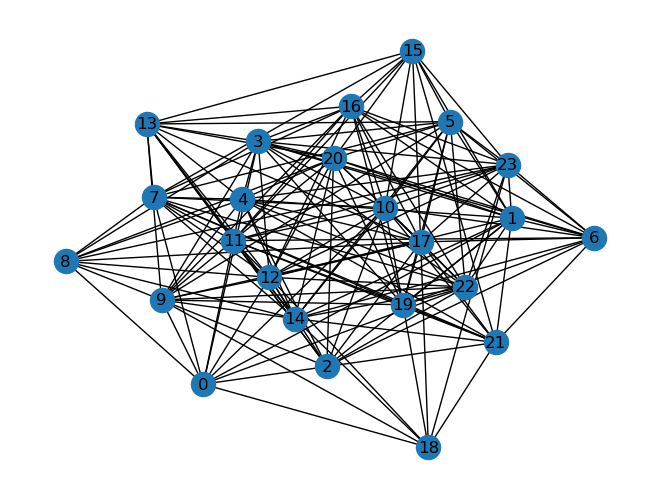

In [2]:
nodes = 24

p = 0.6
G = nx.erdos_renyi_graph(nodes,p=p)


pos = nx.spring_layout(G, seed=42)

adj = nx.adjacency_matrix(G).toarray()

print(adj)



nx.draw( G , with_labels = True,pos=pos) 
plt.show()
# Dstate

In [3]:
a,lsv = get_unitary_la(adj)

In [4]:
print(lsv)

14.010184516396047


In [5]:
np.allclose(a@a.T.conj(),np.eye(2*nodes))

True

In [6]:
subgraph = list(np.random.choice([0,1],size=nodes))

In [7]:
k = sum(subgraph)
subgraph


[0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0]

In [8]:
# break

In [9]:
# subgraph+[0]*nodes
b = np.array(a,dtype=complex)
print(b.shape)
np.abs(expectation_value_permanent(b,subgraph+[0]*nodes))**2

(48, 48)


4.688608318833345e-16

In [10]:
# s_o = [[(0,1),(1,1)]]*nodes+[[(0,1)]]*nodes
state_translator = [ [(i,1)] for i in subgraph]
s_in = state_translator +[[(0,1)]]*nodes
s_o=s_in

sampler = LimOh_sampler(s_in,s_o,b,1000000,verbose=1)
sampler.trust=True


# for _ in range(10):
	# print(np.abs((approx(s_in,s_o,a.T.conj(),size=10000)))**2)

In [11]:
# x = []
# for _ in range(1):
# 	x.append(sampler.approximate(chunk_size=100000))

In [12]:
# plt.plot(list(range(20)),x)

In [13]:
# finder = find_densest_subgraph(G,k,method='exact',verbose=0)

In [14]:
a = find_maxclique(G,method='approximate',verbose=2)
a

24


100%|██████████| 10/10 [00:08<00:00,  1.14it/s]

23



 80%|████████  | 8/10 [00:07<00:01,  1.05it/s]


KeyboardInterrupt: 

In [15]:
list(nx.find_cliques(G))

[[1, 2, 20, 4],
 [1, 2, 20, 12],
 [1, 2, 20, 6],
 [1, 2, 22, 4],
 [1, 2, 22, 12],
 [1, 3, 20, 12],
 [1, 3, 20, 4],
 [1, 3, 20, 5, 19, 6],
 [1, 3, 6, 16, 19],
 [1, 3, 6, 16, 23],
 [1, 3, 6, 5, 23],
 [1, 3, 22, 0, 12],
 [1, 3, 22, 19, 16],
 [1, 3, 22, 19, 5],
 [1, 3, 22, 23, 16, 12],
 [1, 3, 22, 23, 4],
 [1, 3, 22, 23, 5],
 [1, 14, 20, 5, 6],
 [1, 14, 20, 12],
 [1, 14, 20, 4],
 [1, 14, 21, 4],
 [1, 14, 21, 6],
 [1, 14, 22, 5],
 [1, 14, 22, 12],
 [1, 14, 22, 4],
 [1, 15, 16, 23],
 [1, 15, 21],
 [1, 15, 5, 20],
 [1, 15, 5, 23],
 [1, 21, 0],
 [1, 21, 19, 6],
 [4, 3, 8, 20],
 [4, 3, 8, 23],
 [4, 3, 9, 13],
 [4, 3, 9, 22],
 [4, 3, 13, 20],
 [4, 8, 17, 2, 20],
 [4, 8, 17, 23],
 [4, 8, 14, 20],
 [4, 8, 14, 7],
 [4, 11, 21, 14, 7],
 [4, 11, 13, 2, 20],
 [4, 11, 13, 14, 9],
 [4, 11, 13, 14, 20],
 [4, 11, 13, 14, 7],
 [4, 11, 23],
 [4, 17, 9, 13],
 [4, 17, 9, 22],
 [4, 17, 2, 13, 20],
 [4, 17, 2, 22],
 [4, 17, 21],
 [4, 17, 23, 22],
 [4, 22, 9, 14],
 [4, 22, 7, 14],
 [8, 12, 0, 3],
 [8, 12, 0, 7],